In [16]:
import torch
import torchvision
from torchvision import datasets , transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from torch import optim


transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
    ]
)

trainData = datasets.CIFAR10(
    root = './cifar10',
    train = True ,
    download = True ,
    transform = transform
)

testData = datasets.CIFAR10(
    root = './cifar10',
    train = False ,
    download = True ,
    transform = transform
)

trainLoader = DataLoader(
    trainData ,
    batch_size = 4 ,
    shuffle = True
)

testLoader = DataLoader(
    testData ,
    batch_size = 4 ,
    shuffle = True
)

Files already downloaded and verified
Files already downloaded and verified


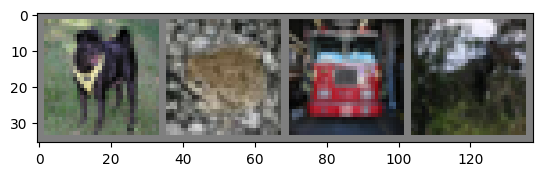

dog   frog  truck deer 


In [11]:
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def imshow(img) :
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg , (1,2,0)))
    plt.show()

# get some random training images
dataiter = iter(trainLoader)
images, labels = next(dataiter)
# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))


In [14]:
class ConvolutionalNeuralNetwork(nn.Module) :
  def __init__(self) :
    super().__init__()
    self.conv1 = nn.Conv2d(3,6,5)
    self.pool = nn.MaxPool2d(2,2)
    self.conv2 = nn.Conv2d(6,16,5)
    self.fc1 = nn.Linear(16*5*5,120)
    self.fc2 = nn.Linear(120,84)
    self.fc3 = nn.Linear(84,10)
  def forward(self,x) :
    x = self.pool(torch.relu(self.conv1(x)))
    x = self.pool(torch.relu(self.conv2(x)))
    x = torch.flatten(x,1)
    x = torch.relu(self.fc1(x))
    x = torch.relu(self.fc2(x))
    x = self.fc3(x)
    return x

In [15]:
model = ConvolutionalNeuralNetwork()
print(model)

ConvolutionalNeuralNetwork(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [17]:
lossFunction = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters() , lr = 0.001 , momentum = 0.9)

In [18]:
epochs = 2
for epoch in range(epochs) :
    running_loss = 0.0
    for i , batch in enumerate(trainLoader , 0) :
        images , labels = batch
        # forward + backward + optimize
        predictions = model(images)
        loss = lossFunction(predictions , labels)
        # Backward pass
        optimizer.zero_grad()  # Clear previous gradients
        loss.backward()        # Compute gradients
        optimizer.step()       # Update parameters
        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0
print("Training Complete!")

[1,  2000] loss: 2.221
[1,  4000] loss: 1.912
[1,  6000] loss: 1.715
[1,  8000] loss: 1.623
[1, 10000] loss: 1.553
[1, 12000] loss: 1.514
[2,  2000] loss: 1.437
[2,  4000] loss: 1.384
[2,  6000] loss: 1.360
[2,  8000] loss: 1.340
[2, 10000] loss: 1.336
[2, 12000] loss: 1.313
Training Complete!


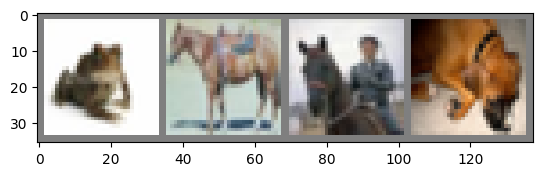

GroundTruth:  frog  horse horse dog  
Predicted:  cat   horse horse frog 


In [21]:
dataiter = iter(testLoader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

predections = model(images)
_ , predicted = torch.max(predections , 1)
print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

In [29]:
correct = 0
with torch.no_grad() :
  for testFeatures, testLabels in testLoader:
    # Forward pass: Get model predictions
    predictions = model.forward(testFeatures)

    # Get the predicted class (the class with the highest probability)
    _, predicted = torch.max(predictions, 1)

    # Count the correct predictions
    correct += (predicted == testLabels).sum().item()
accuracy = correct / 10000 * 100
print(f"Test Accuracy: {accuracy}%")


Test Accuracy: 54.6%


In [31]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for batch in testLoader:
        images, labels = batch
        predections = model(images)
        _, predicted = torch.max(predections, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predicted):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 60.8 %
Accuracy for class: car   is 83.4 %
Accuracy for class: bird  is 17.4 %
Accuracy for class: cat   is 42.6 %
Accuracy for class: deer  is 52.1 %
Accuracy for class: dog   is 47.8 %
Accuracy for class: frog  is 64.0 %
Accuracy for class: horse is 59.0 %
Accuracy for class: ship  is 71.3 %
Accuracy for class: truck is 47.6 %
